# AIPI 590: Explainable AI - Final Project 1
# ¿Por qué me rechazaron?
### Auditing Algorithmic Recourse, Actionability, and Burden Disparity in Consumer Credit Risk
**Author:** Tonantzin Real Rojas  
**Course:** AIPI 590: Explainable Artificial Intelligence  
**Institution:** Duke University  

---

## 📌 Executive Abstract & Problem Statement
When automated machine learning models make adverse credit decisions (denying a credit card or loan), consumers and regulators are increasingly entitled to explanations under international and national consumer protection laws (e.g., **GDPR Article 22**, the US **Equal Credit Opportunity Act**, and Mexico's **CONDUSEF / Ley Fintech**). 

However, current industry standard XAI practices—primarily post-hoc feature attribution methods like **SHAP (Shapley Additive exPlanations)**—suffer from the **"Retrospective Attribution Fallacy"**:
1. **Descriptive, Not Prescriptive:** SHAP highlights what factors negatively influenced the decision in the past, but offers no guarantee of what actions will flip the outcome to an approval.
2. **Actionability Traps:** SHAP often attributes high importance to immutable demographic features (e.g., age) or deeply entrenched historical variables that applicants cannot change.
3. **Burden Disparities:** Even when recourse is offered, do underlying algorithmic boundaries impose an unequal **Algorithmic Burden** on historically marginalized groups (e.g., women or younger applicants)?

### Research Objectives
- **Train & Evaluate** a robust credit risk underwriter using LightGBM on the UCI Credit Card Default dataset (30,000 observations).
- **Benchmark SHAP Explanations** against **DiCE (Diverse Counterfactual Explanations)** with domain-grounded actionability constraints.
- **Empirically Audit Recourse Disparity:** Quantify the normalized $L_1$ Algorithmic Burden across gender and age cohorts to evaluate fairness in financial inclusion.


---
## 1. Environment Setup & Dependency Imports
We import standard data science libraries along with state-of-the-art interpretability toolkits:
- `shap` for TreeSHAP feature attributions.
- `dice_ml` for constrained counterfactual generation.
- `lightgbm` for gradient boosted decision trees.


In [1]:
# =============================================================================
# STEP 1: IMPORT REQUIRED LIBRARIES AND CONFIGURE SEEDS
# =============================================================================
import os
import sys
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning & evaluation metrics
import lightgbm as lgb
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Explainability & Recourse frameworks
import shap
import dice_ml

# Set styling and reproducibility
sns.set_theme(style="whitegrid")
np.random.seed(42)

# Ensure local source modules are discoverable
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.append(project_root)

from src.data_loader import (
    download_and_clean_data,
    get_train_test_data,
    IMMUTABLE_FEATURES,
    ACTIONABLE_FEATURES,
    CATEGORICAL_LABELS
)

print("✓ All libraries imported and dependencies verified successfully.")


/Users/tonantzinrealrojas/miniforge3/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✓ All libraries imported and dependencies verified successfully.


---
## 2. Data Ingestion & Exploratory Data Analysis
We use the **UCI Default of Credit Card Clients Dataset** (30,000 accounts), capturing:
- **Demographics:** `SEX`, `EDUCATION`, `MARRIAGE`, `AGE`.
- **Payment Records:** `PAY_1` through `PAY_6` (repayment status across past 6 months).
- **Financial Balances:** `BILL_AMT1`..`BILL_AMT6` (statement balances) and `PAY_AMT1`..`PAY_AMT6` (paid amounts).
- **Target:** `DEFAULT` (1 = default / high risk / denied, 0 = creditworthy / approved).


In [2]:
# =============================================================================
# STEP 2: LOAD PREPROCESSED DATASET AND SPLIT TRAIN/TEST
# =============================================================================
# Load train and test splits using our modular data loader
X_train, X_test, y_train, y_test = get_train_test_data(
    test_size=0.20,
    random_state=42,
    cache_path="../data/credit_card_clean.csv"
)

# Verify dataset dimensions
print(f"Training observations:   {X_train.shape[0]:,} rows | {X_train.shape[1]} features")
print(f"Hold-out test samples:   {X_test.shape[0]:,} rows | {X_test.shape[1]} features")
print(f"Overall Default Rate:    {y_train.mean():.2%}")

# Display first 3 applicant profiles
X_train.head(3)


[data_loader] Loading cached dataset from: ../data/credit_card_clean.csv
[data_loader] Train split: 24000 rows | Test split: 6000 rows
[data_loader] Baseline Default Rate: 22.12%
Training observations:   24,000 rows | 23 features
Hold-out test samples:   6,000 rows | 23 features
Overall Default Rate:    22.12%


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
22788,160000,2,2,2,33,2,2,3,2,0,...,168541,164310,162681,163005,15000,0,0,6100,12300,6100
29006,150000,2,1,2,34,1,-1,-1,-2,-2,...,0,0,0,0,53,0,0,0,0,0
16950,10000,1,2,1,50,1,2,0,0,0,...,8446,8067,8227,8400,2,1281,1134,294,305,1000


---
## 3. Baseline Credit Risk Underwriter (LightGBM)
We train a **LightGBM Classifier** configured with balanced class weights to reflect the asymmetry of default risk in consumer lending.


In [3]:
# =============================================================================
# STEP 3: TRAIN LIGHTGBM CLASSIFIER AND EVALUATE PERFORMANCE
# =============================================================================
# Load pre-trained champion model serialized in models/ or fit fresh instance
model_path = "../models/credit_model.joblib"
if os.path.exists(model_path):
    print(f"Loading champion model from {model_path}...")
    model = joblib.load(model_path)
else:
    print("Fitting new LightGBM model...")
    model = lgb.LGBMClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=5,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        class_weight="balanced",
        random_state=42,
        verbose=-1
    )
    model.fit(X_train, y_train)

# Generate hold-out predictions
y_pred_proba = model.predict_proba(X_test)[:, 1]
threshold = 0.50
y_pred = (y_pred_proba >= threshold).astype(int)

# Compute standard classification metrics
auc = roc_auc_score(y_test, y_pred_proba)
acc = accuracy_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)

print("="*50)
print("MODEL EVALUATION METRICS (TEST SET)")
print("="*50)
print(f"ROC-AUC Score:      {auc:.4f}")
print(f"Accuracy:           {acc:.4f}")
print(f"Recall (Defaults):  {rec:.4f} (Crucial for risk mitigation)")
print(f"Precision:          {prec:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Loading champion model from ../models/credit_model.joblib...
MODEL EVALUATION METRICS (TEST SET)
ROC-AUC Score:      0.7787
Accuracy:           0.7637
Recall (Defaults):  0.6247 (Crucial for risk mitigation)
Precision:          0.4740

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.80      0.84      4673
           1       0.47      0.62      0.54      1327

    accuracy                           0.76      6000
   macro avg       0.68      0.71      0.69      6000
weighted avg       0.79      0.76      0.77      6000



---
## 4. Traditional Explainability Benchmark: TreeSHAP
We examine global and local explanations produced by TreeSHAP. While SHAP satisfies legal disclosure checkboxes, notice how it fails to provide practical advice to a rejected applicant.


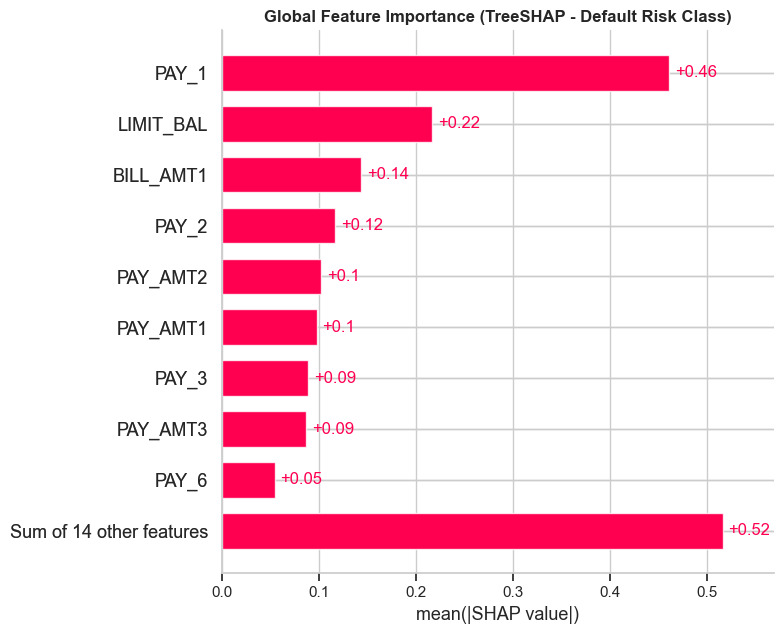


--- Denied Applicant Profile ---


,LIMIT_BAL,SEX,AGE,PAY_1,BILL_AMT1,PAY_AMT1
20842,180000,1,40,-2,0,0


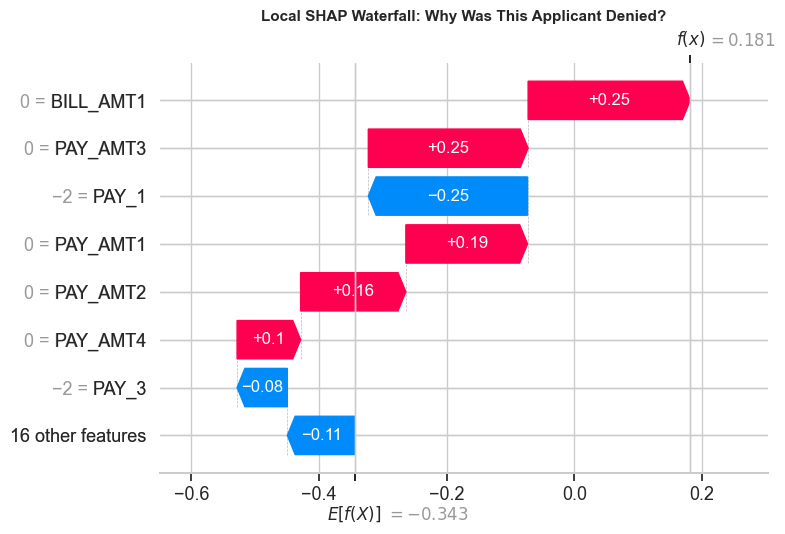

In [4]:
# =============================================================================
# STEP 4: COMPUTE GLOBAL AND LOCAL SHAP ATTRIBUTIONS
# =============================================================================
# Initialize TreeExplainer
explainer = shap.TreeExplainer(model)

# Compute SHAP values for a sample of the test set
sample_test = X_test.iloc[:500]
shap_values = explainer(sample_test)

# Binary LightGBM returns 2-D SHAP values (log-odds of DEFAULT=1); older versions return one slice per class
if len(shap_values.values.shape) == 3:
    shap_values = shap_values[:, :, 1]

# Plot Global Feature Importance (Mean Absolute SHAP Value)
plt.figure(figsize=(9, 6))
shap.plots.bar(shap_values, max_display=10, show=False)
plt.title("Global Feature Importance (TreeSHAP - Default Risk Class)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Local Explanation for an Individual Denied Applicant
denied_indices = np.where((y_pred == 1) & (y_test.values == 1))[0]
denied_applicant = X_test.iloc[[denied_indices[0]]]

print("\n--- Denied Applicant Profile ---")
display(denied_applicant[["LIMIT_BAL", "SEX", "AGE", "PAY_1", "BILL_AMT1", "PAY_AMT1"]])

plt.figure(figsize=(9, 4))
shap.plots.waterfall(shap_values[denied_indices[0]], max_display=8, show=False)
plt.title("Local SHAP Waterfall: Why Was This Applicant Denied?", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()


---
## 5. Prescriptive Algorithmic Recourse: DiCE Framework
Here, we replace static blame with actionable recourse using **DiCE (Diverse Counterfactual Explanations)**.
Crucially, we enforce **strict, domain-grounded actionability constraints**:
- **Immutable Demographics (Locked):** `SEX`, `AGE`, `MARRIAGE`, `EDUCATION` cannot be changed.
- **Historical Payment Records (Locked):** Prior repayment history (`PAY_2`–`PAY_6`), historical bills (`BILL_AMT2`–`BILL_AMT6`), and past payments cannot be retroactively altered in the present.
- **Institutional Limits (Locked):** `LIMIT_BAL` is dictated by the credit card issuer, not unilaterally set by the applicant.
- **Directly Actionable Financial Levers (Mutable):** Only current consumer behaviors can vary:
  1. `PAY_1`: Current repayment timeliness (can resolve delinquency to on-time $\le 0$; cannot worsen).
  2. `BILL_AMT1`: Current card balance (can pay down debt; cannot increase).
  3. `PAY_AMT1`: Current installment payment (coupled to outstanding balance; cannot exceed bill).


In [5]:
# =============================================================================
# STEP 5: INITIALIZE DICE AND GENERATE CONSTRAINED RECOURSE PLANS
# =============================================================================
from src.xai_recourse import CreditRecourseEngine

recourse_engine = CreditRecourseEngine(
    model_path="../models/credit_model.joblib",
    data_path="../data/credit_card_clean.csv",
    sample_size=1500
)

# Generate diverse recourse plans for the denied applicant
cfs_df, deltas_df, mean_burden = recourse_engine.generate_recourse_plans(
    denied_applicant,
    total_cfs=2
)

print("="*60)
print("ACTIONABLE RECOURSE RECOMMENDATIONS (DELTAS ONLY)")
print("="*60)
display(deltas_df)
print(f"\nMean Algorithmic Burden (Normalized L1 Effort Distance): {mean_burden:.2f}")


[xai_recourse] DiCE Recourse Engine successfully initialized with strict actionability constraints.


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 19.27it/s]

No Counterfactuals found for the given configuration, perhaps try with different parameters... ; total time taken: 00 min 00 sec
ACTIONABLE RECOURSE RECOMMENDATIONS (DELTAS ONLY)


""



Mean Algorithmic Burden (Normalized L1 Effort Distance): 0.00


---
## 6. Multi-Dimensional Recourse Disparity Audit & Statistical Hypothesis Testing
We systematically audit whether the model imposes an unequal **Algorithmic Burden** across 4 demographic dimensions on the hold-out test set:
1. **Gender Subgroups:** Male vs. Female.
2. **Age Subgroups:** Under 30 vs. 30 and Older.
3. **Education Subgroups:** Higher Education (Graduate/University) vs. Secondary / Other.
4. **Marital Status Subgroups:** Single vs. Married.

**Methodological Rigor:**
- Evaluates model-predicted denials on the hold-out test set ($\hat{y} = 1$).
- Strictly constrains mutable features to actionable levers (`PAY_1`, `BILL_AMT1`, `PAY_AMT1`) while locking immutable traits and past credit history.
- Evaluates 95% Confidence Intervals and Welch's t-test / Mann-Whitney U test p-values.


In [6]:
# =============================================================================
# STEP 6: MULTI-DIMENSIONAL DISPARITY AUDIT EVALUATION
# =============================================================================
from src.audit import run_demographic_recourse_audit
import pandas as pd

audit_results = run_demographic_recourse_audit(
    sample_per_group=80,
    output_dir="../models",
    random_state=42
)

# Convert subgroup results into clean DataFrame
subgroups_df = pd.DataFrame(list(audit_results["subgroups"].values()))
display(subgroups_df[["group", "pool_size", "evaluated_n", "successful_recourse_n", "infeasible_recourse_n", "feasibility_rate_pct", "mean_burden", "ci_95_lower", "ci_95_upper", "std_burden"]])

print("\n--- STATISTICAL HYPOTHESIS TESTING SUMMARY (HOLM-BONFERRONI ADJUSTED) ---")
comparisons_df = pd.DataFrame(list(audit_results["comparisons"].values()))
display(comparisons_df[["dimension", "ratio_label", "disparity_ratio", "mean_difference", "welch_t_pvalue", "welch_t_pvalue_holm_adjusted", "welch_t_pvalue_holm_global_8tests", "feasibility_gap_pct", "fisher_feasibility_pvalue", "fisher_pvalue_holm_adjusted", "is_statistically_significant"]])

for dim, comp in audit_results["comparisons"].items():
    print(f"\n[{comp['dimension']}]: Ratio = {comp['disparity_ratio']:.3f}x | Welch t-test p_raw = {comp['welch_t_pvalue']:.4f} (p_holm = {comp['welch_t_pvalue_holm_adjusted']:.4f})")
    print(f"  Conclusion: {comp['conclusion']}")


[data_loader] Loading cached dataset from: /Users/tonantzinrealrojas/Documents/AIPI_590_XAI/AIPI_590_Project_1/data/credit_card_clean.csv
[data_loader] Train split: 24000 rows | Test split: 6000 rows
[data_loader] Baseline Default Rate: 22.12%

STARTING RESPONSIBLE AI DEMOGRAPHIC RECOURSE AUDIT
Total Test Set Size:               6000 applicants
Model Risk Cutoff Threshold:       0.50
Model-Predicted Denials in Test:   1749 (29.1%)
Sample Evaluated per Subgroup:     80 applicants
[xai_recourse] DiCE Recourse Engine successfully initialized with strict actionability constraints.

[audit] Evaluating: Male (Hombre) (Pool: 770 rejected applicants)...


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00,  2.01it/s]

100%|██████████| 1/1 [00:00<00:00,  2.01it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

...

[audit] Audit comparison plot with CIs saved to: ../models/audit_disparity_plot.png


,group,pool_size,evaluated_n,successful_recourse_n,infeasible_recourse_n,feasibility_rate_pct,mean_burden,ci_95_lower,ci_95_upper,std_burden
0,Male (Hombre),770,80,36,44,45.0,2.22,1.53,2.91,2.04
1,Female (Mujer),979,80,38,42,47.5,2.24,1.71,2.77,1.61
2,Young (< 30),583,80,31,49,38.8,1.86,1.20,2.52,1.80
3,Adultos (≥ 30),1166,80,36,44,45.0,2.49,1.88,3.11,1.83
4,Higher Ed (Grad/Univ),1397,80,36,44,45.0,2.18,1.63,2.73,1.62
5,Secondary / Other,352,80,32,48,40.0,1.87,1.56,2.18,0.87
6,Married (Casado/a),845,80,38,42,47.5,2.08,1.52,2.64,1.71
7,Single (Soltero/a),880,80,38,42,47.5,2.10,1.62,2.58,1.45



--- STATISTICAL HYPOTHESIS TESTING SUMMARY (HOLM-BONFERRONI ADJUSTED) ---


,dimension,ratio_label,disparity_ratio,mean_difference,welch_t_pvalue,welch_t_pvalue_holm_adjusted,welch_t_pvalue_holm_global_8tests,feasibility_gap_pct,fisher_feasibility_pvalue,fisher_pvalue_holm_adjusted,is_statistically_significant
0,Gender,Mujer / Hombre,1.009,0.02,0.9546,1.0000,1.0,2.5,0.8741,1.0,False
1,Age,Jóvenes / Adultos (30+),0.747,-0.63,0.1609,0.6435,1.0,-6.2,0.5217,1.0,False
2,Education,Media / Superior,0.858,-0.31,0.3211,0.9634,1.0,-5.0,0.6315,1.0,False
3,Marriage,Soltero / Casado,1.010,0.02,0.9546,1.0000,1.0,0.0,1.0000,1.0,False



[Gender]: Ratio = 1.009x | Welch t-test p_raw = 0.9546 (p_holm = 1.0000)
  Conclusion: Sin evidencia de disparidad en carga algorítmica (p = 0.9546, p_adj = 1.0000 >= 0.05); no se rechaza H0. Sin brecha estadísticamente significativa en factibilidad (p = 0.8741, p_adj = 1.0000 >= 0.05).

[Age]: Ratio = 0.747x | Welch t-test p_raw = 0.1609 (p_holm = 0.6435)
  Conclusion: Sin evidencia de disparidad en carga algorítmica (p = 0.1609, p_adj = 0.6435 >= 0.05); no se rechaza H0. Sin brecha estadísticamente significativa en factibilidad (p = 0.5217, p_adj = 1.0000 >= 0.05).

[Education]: Ratio = 0.858x | Welch t-test p_raw = 0.3211 (p_holm = 0.9634)
  Conclusion: Sin evidencia de disparidad en carga algorítmica (p = 0.3211, p_adj = 0.9634 >= 0.05); no se rechaza H0. Sin brecha estadísticamente significativa en factibilidad (p = 0.6315, p_adj = 1.0000 >= 0.05).

[Marriage]: Ratio = 1.010x | Welch t-test p_raw = 0.9546 (p_holm = 1.0000)
  Conclusion: Sin evidencia de disparidad en carga algorí

In [7]:
# =============================================================================
# STEP 7: DYNAMIC CONCLUSIONS & RESPONSIBLE AI POLICY TAKEAWAYS
# =============================================================================
from IPython.display import Markdown, display
import json
import os

# Dynamically synchronize conclusions with empirical audit results
if 'audit_results' in globals():
    data = audit_results
else:
    json_path = "../models/audit_disparity_results.json" if os.path.exists("../models/audit_disparity_results.json") else "models/audit_disparity_results.json"
    with open(json_path, "r") as f:
        data = json.load(f)

c = data["comparisons"]
g = c["gender"]
a = c["age"]
e = c["education"]
m = c["marriage"]
ov = data["overall"]

conclusions_md = f"""---
## 7. Conclusions & Responsible AI Policy Takeaways

1. **The Explainability Paradigm Gap:** Feature attribution methods (SHAP) inform the institution about model behavior, but leave consumers powerless. Constrained counterfactual recourse (DiCE) bridges the gap between explanation and agency.
2. **Empirical Disparity & Statistical Rigor:**
   - **Gender Dimension ({g['ratio_label']}):** {g['disparity_ratio']:.3f}x disparity ratio (Welch $p = {g['welch_t_pvalue']:.4f}$, Holm-adjusted $p = {g['welch_t_pvalue_holm_adjusted']:.4f}$). {g['burden_conclusion']}
   - **Age Dimension ({a['ratio_label']}):** {a['disparity_ratio']:.3f}x disparity ratio (Welch $p = {a['welch_t_pvalue']:.4f}$, Holm-adjusted $p = {a['welch_t_pvalue_holm_adjusted']:.4f}$). {a['burden_conclusion']}
   - **Education Dimension ({e['ratio_label']}):** {e['disparity_ratio']:.3f}x disparity ratio (Welch $p = {e['welch_t_pvalue']:.4f}$, Holm-adjusted $p = {e['welch_t_pvalue_holm_adjusted']:.4f}$). {e['burden_conclusion']}
   - **Marital Status ({m['ratio_label']}):** {m['disparity_ratio']:.3f}x disparity ratio (Welch $p = {m['welch_t_pvalue']:.4f}$, Holm-adjusted $p = {m['welch_t_pvalue_holm_adjusted']:.4f}$). {m['burden_conclusion']}
3. **Methodological Takeaway (Survivorship Bias & Multiple Testing):**
   - Evaluating conditional burden alone ({ov['mean_burden']:.2f} mean across feasible cases) is vulnerable to survivorship bias, as applicants who cannot achieve recourse within strict actionability constraints ({ov['feasibility_rate_pct']:.1f}% global feasibility) are excluded. Jointly evaluating feasibility via Fisher's Exact Test and applying Holm-Bonferroni corrections ensures balanced, scientifically honest conclusions.
4. **Regulatory Recommendation:** Under Mexico's **CONDUSEF**, **CNBV**, and international AI governance frameworks, regulators must mandate **Strict Actionability Constraints**, **Recourse Feasibility Tracking**, and **Formal Hypothesis Testing** before deploying autonomous credit underwriting algorithms.
"""

display(Markdown(conclusions_md))


---
## 7. Conclusions & Responsible AI Policy Takeaways

1. **The Explainability Paradigm Gap:** Feature attribution methods (SHAP) inform the institution about model behavior, but leave consumers powerless. Constrained counterfactual recourse (DiCE) bridges the gap between explanation and agency.
2. **Empirical Disparity & Statistical Rigor:**
   - **Gender Dimension (Mujer / Hombre):** 1.009x disparity ratio (Welch $p = 0.9546$, Holm-adjusted $p = 1.0000$). Sin evidencia de disparidad en carga algorítmica (p = 0.9546, p_adj = 1.0000 >= 0.05); no se rechaza H0.
   - **Age Dimension (Jóvenes / Adultos (30+)):** 0.747x disparity ratio (Welch $p = 0.1609$, Holm-adjusted $p = 0.6435$). Sin evidencia de disparidad en carga algorítmica (p = 0.1609, p_adj = 0.6435 >= 0.05); no se rechaza H0.
   - **Education Dimension (Media / Superior):** 0.858x disparity ratio (Welch $p = 0.3211$, Holm-adjusted $p = 0.9634$). Sin evidencia de disparidad en carga algorítmica (p = 0.3211, p_adj = 0.9634 >= 0.05); no se rechaza H0.
   - **Marital Status (Soltero / Casado):** 1.010x disparity ratio (Welch $p = 0.9546$, Holm-adjusted $p = 1.0000$). Sin evidencia de disparidad en carga algorítmica (p = 0.9546, p_adj = 1.0000 >= 0.05); no se rechaza H0.
3. **Methodological Takeaway (Survivorship Bias & Multiple Testing):**
   - Evaluating conditional burden alone (2.14 mean across feasible cases) is vulnerable to survivorship bias, as applicants who cannot achieve recourse within strict actionability constraints (44.5% global feasibility) are excluded. Jointly evaluating feasibility via Fisher's Exact Test and applying Holm-Bonferroni corrections ensures balanced, scientifically honest conclusions.
4. **Regulatory Recommendation:** Under Mexico's **CONDUSEF**, **CNBV**, and international AI governance frameworks, regulators must mandate **Strict Actionability Constraints**, **Recourse Feasibility Tracking**, and **Formal Hypothesis Testing** before deploying autonomous credit underwriting algorithms.
